# Week 4 - Federated averaging (FedAvg) prototype

Goal: verify FedAvg is implemented correctly (independent of how accurate it is) and run a 10-round prototype.

**Rules carried over from Week 3:** the scaler is the Week 3 one (fitted on training users only - not refitted here), the starting weights are mlp_initial_state.pt (the same ones the central MLP used), only validation users are scored, and test users are never loaded.

### Reading task: map McMahan et al. (2017) Algorithm 1 to this notebook
Fill in this table while you read the paper - it is part of the learning, so it is left blank on purpose.

| Symbol in Algorithm 1 | Meaning in the paper | Name / value in this notebook |
|---|---|---|
| $K$ | | |
| $C$ | | |
| $m = \max(C \cdot K, 1)$ | | |
| $S_t$ | | |
| $n_k$, $n$ | | |
| $B$ | | |
| $E$ | | |
| $\eta$ | | |
| $w_t$, $w_{t+1}^k$ | | |

## Settings 

In [5]:
from pathlib import Path
import json, copy, time, platform
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix

# ---- Paths ----------------------------------------------------------------
PROJECT       = Path.cwd()                              # run the notebook from the repo root
FEATURE_TABLE = PROJECT / "features_watch.parquet"
SPLIT_FILE    = PROJECT / "split_manifest.csv"
WEEK3         = PROJECT / "WISDM_baseline_outputs"       # scaler, label map, initial weights from Week 3
OUTPUT        = PROJECT / "WISDM_fedavg_outputs"         # every Week 4 file goes here
CHECKPOINTS   = OUTPUT / "checkpoints"
CHECKPOINTS.mkdir(parents=True, exist_ok=True)

# ---- Frozen settings ---------------------------------------------------------
SEED              = 42
HIDDEN            = 128
BATCH_SIZE        = 64       # B in Algorithm 1
CLIENTS_PER_ROUND = 10       # m in Algorithm 1
LOCAL_EPOCHS      = 1        # E in Algorithm 1 (Week 5 compares 1 vs 3)
LR                = 0.01     # eta in Algorithm 1
PROTOTYPE_ROUNDS  = 10       # this week
PLANNED_ROUNDS    = 100      # the Week 5 cap we need a runtime estimate for

torch.set_num_threads(1)     # same as Week 3, so timings are comparable

# Labels and feature order come from Week 3's saved files - never re-typed by hand.
label_map = json.loads((WEEK3 / "label_map.json").read_text())
LABELS    = [d["code"] for d in label_map["labels"]]
LABEL_IDS = [d["id"] for d in label_map["labels"]]
FEATURES  = label_map["feature_order"]
LABEL_TO_ID = {c: i for i, c in zip(LABEL_IDS, LABELS)}
assert LABELS == list("ABCDEFGHIJKLMOPQRS") and LABEL_IDS == list(range(18)) and len(FEATURES) == 30
print("Outputs go to:", OUTPUT)

Outputs go to: C:\Users\Daniel Busing\Desktop\Personal\China-Internship\NCP-Wearables\WISDM_fedavg_outputs


## Data and clients

One **client = one training participant**. Each client holds only its own windows, already scaled with the
*Week 3 training scaler*. `N_K[user]` is $n_k$: the number of valid training windows on that client.

In [6]:
frame = pd.read_parquet(FEATURE_TABLE)
manifest = pd.read_csv(SPLIT_FILE)
manifest["split"] = manifest["split"].replace({"eval": "validation"})
SPLIT_OF_USER = dict(zip(manifest["Subject_ID"], manifest["split"]))
frame["split"] = frame["Subject_ID"].map(SPLIT_OF_USER)
assert frame["window_id"].is_unique and frame["split"].notna().all()

# Keep train + validation only. Test users are not loaded at all this week.
frame = frame[frame["split"].isin(["train", "validation"])].reset_index(drop=True)
frame["y"] = frame["Activity_Code"].map(LABEL_TO_ID).astype(int)

# Re-use the Week 3 scaler (fitted on training users only). Do NOT fit a new one.
scaler = joblib.load(WEEK3 / "scaler.joblib")
assert list(scaler.feature_names_in_) == FEATURES
X_all = scaler.transform(frame[FEATURES])

def to_tensors(mask):
    X = torch.tensor(X_all[mask], dtype=torch.float32)
    y = torch.tensor(frame.loc[mask, "y"].to_numpy(), dtype=torch.long)
    return X, y

# ---- Clients: {user_id: {"X": tensor, "y": tensor, "n": number of windows}} ------------
train_mask = (frame["split"] == "train").to_numpy()
CLIENT_IDS = sorted(frame.loc[train_mask, "Subject_ID"].unique().tolist())
CLIENTS = {}
for u in CLIENT_IDS:
    X, y = to_tensors((frame["Subject_ID"] == u).to_numpy() & train_mask)
    CLIENTS[u] = {"X": X, "y": y, "n": len(y)}
N_K = {u: c["n"] for u, c in CLIENTS.items()}

# ---- Validation set (pooled, scored after every round) ---------------------------------
val_mask = (frame["split"] == "validation").to_numpy()
X_val_t, y_val_t = to_tensors(val_mask)
y_val, users_val = y_val_t.numpy(), frame.loc[val_mask, "Subject_ID"].to_numpy()

assert len(CLIENT_IDS) == 31 and sum(N_K.values()) == int(train_mask.sum())
assert not set(CLIENT_IDS) & set(users_val)
print(f"{len(CLIENT_IDS)} clients, {sum(N_K.values())} training windows "
      f"(per client: min {min(N_K.values())}, max {max(N_K.values())})")
print(f"Validation: {len(set(users_val))} users, {len(y_val)} windows")

31 clients, 9321 training windows (per client: min 272, max 308)
Validation: 10 users, 3060 windows


## Model, initial weights and evaluator 

Identical to Week 3 evaluate() is a copy of the Week 3 function - it must stay identical so central and federated
scores are comparable. INITIAL_STATE is the saved Week 3 starting point; FedAvg's global model $w_0$ starts here.

In [7]:
class MLP(nn.Module):
    def __init__(self, n_in=len(FEATURES), n_hidden=HIDDEN, n_out=len(LABELS)):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_in, n_hidden), nn.ReLU(), nn.Linear(n_hidden, n_out))

    def forward(self, x):
        return self.net(x)

loss_fn = nn.CrossEntropyLoss()
INITIAL_STATE = torch.load(WEEK3 / "mlp_initial_state.pt")     # w_0 - treat as read-only!

def predict_logits(model, X):
    model.eval()
    with torch.no_grad():
        return model(X)

def evaluate(y_true, y_pred, subjects):
    # Same metric definitions as Week 3.
    y_true, y_pred, subjects = map(np.asarray, (y_true, y_pred, subjects))
    per_user_f1 = pd.Series({u: f1_score(y_true[subjects == u], y_pred[subjects == u],
                                         labels=LABEL_IDS, average="macro", zero_division=0)
                             for u in np.unique(subjects)})
    return {
        "macro_f1": f1_score(y_true, y_pred, labels=LABEL_IDS, average="macro", zero_division=0),
        "accuracy": accuracy_score(y_true, y_pred),
        "mean_user_macro_f1": per_user_f1.mean(),
        "_per_class_recall": recall_score(y_true, y_pred, labels=LABEL_IDS, average=None, zero_division=0),
        "_confusion": confusion_matrix(y_true, y_pred, labels=LABEL_IDS),
    }

def evaluate_state(state):
    # Load a state_dict into a fresh model and score it on the validation users.
    model = MLP()
    model.load_state_dict(state)
    logits = predict_logits(model, X_val_t)
    result = evaluate(y_val, logits.argmax(1).numpy(), users_val)
    result["val_loss"] = loss_fn(logits, y_val_t).item()
    return result

def states_equal(a, b, atol=0.0):
    # True if two state_dicts have the same keys and (almost) the same values.
    return a.keys() == b.keys() and all(torch.allclose(a[k], b[k], atol=atol, rtol=0) for k in a)

# Consistency with Week 3: the untrained model must score exactly what Week 3 recorded at epoch 0.
init_scores = evaluate_state(INITIAL_STATE)
week3_epoch0 = pd.read_csv(WEEK3 / "mlp_history.csv").query("epoch == 0").val_macro_f1.iloc[0]
assert np.isclose(init_scores["macro_f1"], week3_epoch0), "initial weights / scaler differ from Week 3"
print(f"Initial model validation Macro F1 = {init_scores['macro_f1']:.4f} (matches Week 3 epoch 0)")

Initial model validation Macro F1 = 0.0331 (matches Week 3 epoch 0)


## `sample_clients`

Each round, FedAvg picks a random set $S_t$ of $m$ clients. 

* sample **without replacement** (a client cannot appear twice in the same round),
* use **10** clients, or **all** clients if fewer than 10 are available,
* the sampling must be **reproducible**: use the random generator `rng` that is passed in - do not create a new one
  inside the function and do not use Python's `random` module.
* return a plain Python `list` of user IDs, **sorted** (makes the logs easier to read).

<details><summary>Hint 1 (concept)</summary>

A NumPy `Generator` (made with `np.random.default_rng(seed)`) has a method that picks items from an array, with an option
to forbid repeats. Because the generator object keeps its internal state between calls, calling your function once per
round gives a *different* sample each round but the *same sequence* of samples every time you rerun with the same seed.
</details>

<details><summary>Hint 2 (API)</summary>

`rng.choice(a, size=..., replace=...)`. Use `min(k, len(client_ids))` for the size. Convert the result with `.tolist()`
and wrap it in `sorted(...)`.
</details>

In [8]:
def sample_clients(rng, client_ids, k=CLIENTS_PER_ROUND):
    """Return a sorted list of min(k, len(client_ids)) distinct client IDs, drawn with `rng`."""
    samples = rng.choice(client_ids, size = min(k, len(client_ids)), replace = False) #Min (k, len(client_ids)) to take remaining clients when less than 10 left
    samples = sorted(samples.tolist())
    
    return samples

In [9]:
# TEST (PROVIDED) - run after writing sample_clients
r = np.random.default_rng(SEED)
s1, s2 = sample_clients(r, CLIENT_IDS), sample_clients(r, CLIENT_IDS)
assert isinstance(s1, list) and len(s1) == 10, "should return a list of 10 IDs"
assert len(set(s1)) == 10, "a client appears twice -> must sample WITHOUT replacement"
assert set(s1) <= set(CLIENT_IDS) and s1 == sorted(s1)
assert s1 != s2, "two rounds gave the same clients -> are you re-creating the generator inside the function?"
assert sample_clients(np.random.default_rng(SEED), CLIENT_IDS) == s1, "not reproducible with the same seed"
assert sample_clients(r, CLIENT_IDS[:4]) == sorted(CLIENT_IDS[:4]), "with fewer than 10 clients, use all of them"
print("OK sample_clients:", s1)

OK sample_clients: [1605, 1607, 1618, 1624, 1625, 1629, 1632, 1638, 1641, 1650]


## `local_train` (ClientUpdate in Algorithm 1)

One selected client trains its **own copy** of the current global model on its **own windows**:

1. Make a fresh `MLP()` and load the global weights into it.
2. Make a **fresh** `torch.optim.SGD` optimizer (no momentum) for that model - never reuse an optimizer between clients.
3. Shuffle the client's data into mini-batches of `BATCH_SIZE` with a `DataLoader` whose shuffling is seeded with `seed`.
4. Run `epochs` passes over the data with the standard loop from Week 3
   (`train()` -> `zero_grad` -> forward -> loss -> `backward` -> `step`).
5. Return `(new_state, mean_loss)` where `new_state` is a state_dict that is **independent** of the model object and
   of `global_state`, and `mean_loss` is the average training loss over all samples seen during local training.

`global_state` must not change at all after calling this function. Step 6 checks this.

<details><summary>Hint 1 (concept)</summary>

Your Week 3 `train_mlp` function already does steps 1-4 for the central model. The differences: data is one client's
tensors instead of the whole training set, there is no validation inside the loop, and you return the weights instead
of keeping a best checkpoint.
</details>

<details><summary>Hint 2 (independence)</summary>

`model.state_dict()` returns tensors that *share memory* with the model's parameters. If you return it directly and
something later trains or edits that model, your "saved" weights change too. `copy.deepcopy(...)` makes a real copy.
(Read the PyTorch "saving and loading models" note on this.)
</details>

<details><summary>Hint 3 (reproducible shuffling)</summary>

`DataLoader(TensorDataset(X, y), batch_size=BATCH_SIZE, shuffle=True, generator=torch.Generator().manual_seed(seed))`.
For the mean loss, accumulate `loss.item() * len(yb)` and divide by the total number of samples seen.
</details>

In [40]:
def local_train(global_state, X, y, lr=LR, epochs=LOCAL_EPOCHS, seed=SEED):
    """Train a copy of the global model on one client's data.

    Returns (new_state, mean_loss). Must not modify global_state.
    """
    # 1. Make fresh MLP instance and load the global weights into it
    model = MLP() #Init MLP
    model.load_state_dict(global_state) #init global state/weights for the model

    # 2. Fresh Optimizer
    optimizer = torch.optim.SGD(model.parameters(), lr = lr, momentum = 0.0)

    #3. Seeded DataLoader over client data only
    loader = DataLoader(TensorDataset(X,y), batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))

    # Set counters
    total_loss, seen, updates = 0.0, 0, 0
    
    #4. Run epochs
    for epoch in range (epochs): 
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad() # clear gradients
            logits = model(xb) # forward pass
            loss = loss_fn(logits, yb) # calc cross-entropy loss
            loss.backward() # backpropagation with respect to gradient loss
            optimizer.step() # update weights of model
            total_loss += loss.item() * len(yb) # Last batch is smaller so weighting by batch to give true average loss per window
            seen += len(yb)
            updates += 1

    new_state = copy.deepcopy(model.state_dict())
    mean_loss = total_loss / seen
    
    return new_state, mean_loss

In [41]:
# TEST (PROVIDED) - basic behaviour only; the independence checks are yours to write in Step 6
c = CLIENTS[CLIENT_IDS[0]]
before = copy.deepcopy(INITIAL_STATE)
state_a, loss_a = local_train(INITIAL_STATE, c["X"], c["y"], lr=LR, epochs=1, seed=SEED)
state_b, loss_b = local_train(INITIAL_STATE, c["X"], c["y"], lr=LR, epochs=1, seed=SEED)
assert isinstance(state_a, dict) and state_a.keys() == INITIAL_STATE.keys(), "return a state_dict"
assert all(state_a[k].shape == INITIAL_STATE[k].shape for k in state_a)
assert np.isfinite(loss_a) and loss_a > 0, "mean_loss should be a positive number"
assert not states_equal(state_a, INITIAL_STATE), "training did not change the weights"
assert states_equal(state_a, state_b) and loss_a == loss_b, "same seed should give identical results"
assert states_equal(INITIAL_STATE, before), "local_train modified the global state!"
print(f"OK local_train: client {CLIENT_IDS[0]}, {c['n']} windows, mean local loss {loss_a:.4f}")

OK local_train: client 1604, 306 windows, mean local loss 2.8981


## `aggregate` function

The server combines the selected clients' models, **parameter by parameter**:

$$w_{t+1} = \frac{\sum_{k \in S_t} n_k \, w_{t+1}^k}{\sum_{k \in S_t} n_k}$$

* `states` is a list of state_dicts (one per **selected** client), `counts` the matching list of $n_k$.
* $n_k$ = number of valid training **windows** on client $k$ - not the number of batches, and **not** multiplied by the
  number of local epochs.
* Only the selected clients are in the sum (the denominator is the total of *their* windows, not all 9,321).
* Return a **new** state_dict; do not modify any of the input states.

<details><summary>Hint 1 (concept)</summary>

A state_dict is a dictionary `{parameter_name: tensor}`. Loop over the parameter names of the first state, and for each
name build the weighted sum over clients, then divide by the total count.
</details>

<details><summary>Hint 2 (avoid in-place edits)</summary>

`n * state[name]` creates a **new** tensor, so `sum(n * s[name] for s, n in zip(states, counts))` never touches the
inputs. Avoid `+=` on a tensor that came from one of the input states - that edits it in place.
</details>

In [12]:
def aggregate(states, counts):
    """Weighted average of state_dicts: sum(n_k * w_k) / sum(n_k). Returns a new state_dict."""
    
    total = sum(counts) # Denominator for equation - sum of n_k over the selected clients
    
    new_states = {}
    
    # Federated Averaging Algorithm
    for name in states[0]:
        new_states[name] = sum(n * s[name] for s, n in zip(states, counts)) / total
    
    return new_states

In [13]:
# TEST (PROVIDED) - shape test only; the numerical checks are yours in Step 6
agg = aggregate([state_a, INITIAL_STATE], [3, 1])
assert agg.keys() == INITIAL_STATE.keys() and all(agg[k].shape == INITIAL_STATE[k].shape for k in agg)
print("OK aggregate returns a state_dict of the right shape")

OK aggregate returns a state_dict of the right shape


## Correctness checks 

These checks prove FedAvg is right **before** we look at accuracy. Use the provided `record()` helper so every check
writes one line `PASS: ...` or `FAIL: ...` to the right log. Write at least these checks:

**`aggregation_checks.txt`**
1. Scalar models with value 2 and 8, weighted by counts 1 and 3, aggregate to **6.5**.
   (A "scalar model" can be a state_dict with a single tensor: `{"w": torch.tensor(2.0)}`.)
2. Aggregating a **single** client gives exactly that client's model.
3. Equal-size clients give the plain mean (pick any two real client states with counts `[1, 1]`).
4. The result does not depend on the order of the clients (shuffle `states` and `counts` together).

**`independence_checks.txt`**
5. Training client A does **not** change the global state.
6. Mutating client A's returned state (e.g. add 1.0 to one of its tensors in place with `+=`) does **not** change
   client B's state or the global state.
7. Mutating the **aggregated** state does not change any of the client states that went into it.
8. With **learning rate 0**, a local update returns the initial model (within `atol=1e-7`), and one full round
   (local updates of several clients + aggregate) also returns the initial model.

<details><summary>Hint (how to test "does not change")</summary>

Take a `copy.deepcopy` snapshot **before** the action, do the action, then compare with `states_equal(snapshot, current)`.
For check 6, also try `state_a[k].data_ptr() != state_b[k].data_ptr()` - two tensors that share memory have the same pointer.
</details>

In [42]:
def record(log, name, passed, detail=""):
    # PROVIDED helper: adds one PASS/FAIL line to a log and prints it.
    line = f"{'PASS' if passed else 'FAIL'}: {name}" + (f"  [{detail}]" if detail else "")
    log.append(line)
    print(line)

aggregation_log, independence_log = [], []

user_a, user_b = CLIENT_IDS[0], CLIENT_IDS[1]
state_a, _ = local_train(INITIAL_STATE, CLIENTS[user_a]["X"], CLIENTS[user_a]["y"], seed = SEED + user_a)
state_b, _ = local_train(INITIAL_STATE, CLIENTS[user_b]["X"], CLIENTS[user_b]["y"], seed = SEED + user_b)
NAME = "net.0.weight"

#Aggregation Checks
# Test 1: Scalar 2.0 & 8.0 gives 6.5 
result = aggregate([{"w": torch.tensor(2.0)}, {"w": torch.tensor(8.0)}], [1, 3])
record(aggregation_log, "scalar models 2 & 8 with counts 1 and 3 gives 6.5",
       torch.isclose(result["w"], torch.tensor(6.5)).item(),
                     detail = f"got {result['w'].item()}")

# Test 2: Once client average to itself? 
one = aggregate([state_a], [N_K[user_a]])
record(aggregation_log, "one client aggregate equals that client's model",
       states_equal(one, state_a, atol=1e-7),
       detail=f"client {user_a}, n_k={N_K[user_a]}")

#Test 3: Equal counts give the plain mean parameter by parameter
expected = {name: (state_a[name] + state_b[name]) / 2 for name in state_a}
record(aggregation_log, "equal counts [1,1] give the plain mean of two clients", 
       states_equal(aggregate([state_a, state_b], [1,1]), expected, atol=1e-7))

# Test 4: The order of the clients does not matter
ab = aggregate([state_a, state_b], [N_K[user_a], N_K[user_b]])
ba = aggregate([state_b, state_a], [N_K[user_b], N_K[user_a]])
record(aggregation_log, "aggregate does not depend on the client order",
       states_equal(ab, ba, atol=1e-7))

# Independence Checks: 
# Test 5: Local training must not change the global state
global_before = copy.deepcopy(INITIAL_STATE)
_ = local_train(INITIAL_STATE, CLIENTS[user_a]["X"], CLIENTS[user_a]["y"])
record(independence_log, "local training does not change the global state",
       states_equal(global_before, INITIAL_STATE))

# Test 6: Editing Client A's returned weights in place does not change Client B's or the global state
client_a, _ = local_train(INITIAL_STATE, CLIENTS[user_a]["X"], CLIENTS[user_a]["y"])
client_b, _ = local_train(INITIAL_STATE, CLIENTS[user_b]["X"], CLIENTS[user_b]["y"])
b_before = copy.deepcopy(client_b)
client_a[NAME] += 1.0 # in-place dit
shared_mem = any(client_a[k].data_ptr() in (client_b[k].data_ptr(), INITIAL_STATE[k].data_ptr()) for k in client_a) # same pointer == same mem
record(independence_log, "mutating client A does not change client B or the global state",
       states_equal(client_b, b_before) and states_equal(INITIAL_STATE, global_before) 
       and not shared_mem)

# Test 7: Editing the Aggregated weights in place must not change the clients the went into the aggregation
agg = aggregate([state_a, state_b], [N_K[user_a], N_K[user_b]])
a_before, b_before = copy.deepcopy(state_a), copy.deepcopy(state_b)
agg[NAME] += 5.0
record(independence_log, "mutating the aggregate does not change the client states",
       states_equal(state_a, a_before) and states_equal(state_b, b_before))

# Test 8: lr = 0 to a local update returns the inital model
zero_local, _ = local_train(INITIAL_STATE, CLIENTS[user_a]["X"], CLIENTS[user_a]["y"], lr = 0.0)
record(independence_log, "lr = 0 returns the inital model weights with no updates", 
       states_equal(zero_local, INITIAL_STATE, atol=1e-7))

# Test 9: Lr = 0 to a full round (several clients + aggregation) returns the inital model
round_clients = CLIENT_IDS[:5]
zero_states = [local_train(INITIAL_STATE, CLIENTS[u]["X"], CLIENTS[u]["y"], lr = 0.0)[0] for u in round_clients]
zero_round = aggregate(zero_states, [N_K[u] for u in round_clients])
record(independence_log, "lr = 0.0 for one full training loop still returns the inital model weights w/o any updates",
       states_equal(zero_round, INITIAL_STATE, atol=1e-7))
          
# Save the logs
(OUTPUT / "aggregation_checks.txt").write_text("\n".join(aggregation_log) + "\n")
(OUTPUT / "independence_checks.txt").write_text("\n".join(independence_log) + "\n")
assert all(l.startswith("PASS") for l in aggregation_log + independence_log), "fix the FAIL lines before running FedAvg"

PASS: scalar models 2 & 8 with counts 1 and 3 gives 6.5  [got 6.5]
PASS: one client aggregate equals that client's model  [client 1604, n_k=306]
PASS: equal counts [1,1] give the plain mean of two clients
PASS: aggregate does not depend on the client order
PASS: local training does not change the global state
PASS: mutating client A does not change client B or the global state
PASS: mutating the aggregate does not change the client states
PASS: lr = 0 returns the inital model weights with no updates
PASS: lr = 0.0 for one full training loop still returns the inital model weights w/o any updates


## 'run_fedavg` (10-round prototype)

Put the pieces together (this is the *Server executes* part of Algorithm 1). For each round `t = 1 ... n_rounds`:

1. `selected = sample_clients(rng, CLIENT_IDS, clients_per_round)` - create `rng = np.random.default_rng(seed)` **once,
   before the loop**.
2. For each selected client: `local_train(global_state, ...)` starting from the **current** global state. Give each
   client a different, reproducible shuffle seed, e.g. `seed + 1000 * t + user`.
3. `global_state = aggregate(client_states, [N_K[u] for u in selected])`.
4. `evaluate_state(global_state)` on validation.
5. Save the round's checkpoint with `torch.save(global_state, CHECKPOINTS / f"{tag}_round{t:03d}.pt")`.
6. Append one row to the history (columns below). Time each round with `time.perf_counter()`.

Also add a **round 0** row that scores the initial model (empty `selected_users`), so the curve starts at the beginning.

**Required history columns** (`REQUIRED_COLUMNS` below - the self-check in Step 10 uses them):

| column | content |
|---|---|
| `round` | 0, 1, ..., n_rounds |
| `selected_users` | user IDs joined with `;` e.g. `"1604;1607;..."` (empty string in round 0) |
| `sample_counts` | the matching $n_k$ joined with `;` |
| `total_samples` | sum of the counts |
| `mean_local_loss` | mean of the clients' local losses, **weighted by $n_k$** (NaN in round 0) |
| `val_macro_f1`, `val_accuracy`, `val_mean_user_macro_f1`, `val_loss` | from `evaluate_state` |
| `round_time_s` | seconds for this round (training + aggregation + evaluation) |
| `elapsed_s` | cumulative seconds since the start of the run |

After the run, choose the **prototype checkpoint**: the round with the best validation Macro F1 (ties -> earlier round),
and save it as `fedavg_prototype.pt` in this format:
`{"state_dict": ..., "round": ..., "val_macro_f1": ..., "lr": ..., "local_epochs": ..., "clients_per_round": ..., "label_order": LABELS, "feature_order": FEATURES}`.

In [43]:
REQUIRED_COLUMNS = ["round", "selected_users", "sample_counts", "total_samples", "mean_local_loss",
                    "val_macro_f1", "val_accuracy", "val_mean_user_macro_f1", "val_loss",
                    "round_time_s", "elapsed_s"]

def run_fedavg(n_rounds, lr=LR, local_epochs=LOCAL_EPOCHS, clients_per_round=CLIENTS_PER_ROUND,
               seed=SEED, tag="fedavg"):
    """Run FedAvg from INITIAL_STATE. Returns (history DataFrame, final global state)."""

    rng = np.random.default_rng(seed)
    global_state = copy.deepcopy(INITIAL_STATE) #w0
    t_start = time.perf_counter() #init timer
    
    scores = evaluate_state(global_state)
    
    rows = [{"round" : 0, "selected_users": "", "sample_counts": "", "total_samples": 0, "mean_local_loss": np.nan,
                "val_macro_f1": scores["macro_f1"], "val_accuracy" : scores["accuracy"], "val_mean_user_macro_f1": scores["mean_user_macro_f1"],
                 "val_loss": scores["val_loss"], "round_time_s": time.perf_counter() - t_start, "elapsed_s": time.perf_counter() - t_start}]
    
    
    for r in range(1, n_rounds + 1):
        r_round = time.perf_counter()
        # Pick the rounds clients w/ random selection w/o subsitution
        selected = sample_clients(rng, CLIENT_IDS, clients_per_round) #S_t
        # For each selected client train a copy of the current global model
        client_states, client_loss = [], []
        #Client loop
        for user in selected:
            state, loss = local_train(global_state,CLIENTS[user]["X"], CLIENTS[user]["y"], lr=lr, epochs=local_epochs, seed = seed + 2000 * r + user)
            client_states.append(state)
            client_loss.append(loss)
        # Take weighted average and send update to global model
        counts = [N_K[user] for user in selected] # window counts of selected clients
        global_state = aggregate(client_states, counts)
        scores = evaluate_state(global_state)
        torch.save(global_state, CHECKPOINTS / f"{tag}_round{r:03d}.pt")
        rows.append({
            "round": r, 
            "selected_users": ";".join(map(str, selected)),
            "sample_counts": ";".join(map(str, counts)),
            "total_samples": sum(counts),
            "mean_local_loss": np.average(client_loss, weights=counts), 
            "val_macro_f1": scores["macro_f1"], 
            "val_accuracy": scores["accuracy"],
            "val_mean_user_macro_f1": scores["mean_user_macro_f1"],
            "val_loss": scores["val_loss"],
            "round_time_s": time.perf_counter() - r_round, 
            "elapsed_s": time.perf_counter() - t_start,
            })
        print(f"round {r: >3}: val Macro F1: {scores['macro_f1']:.4f}") # Print Progress
    
    history = pd.DataFrame(rows)[REQUIRED_COLUMNS]
    
    return history, global_state

h, s = run_fedavg(0); display(h)   # one row, round 0, real validation numbers
h, s = run_fedavg(2); display(h)   # 3 rows; different selected_users in rounds 1 and 2

,round,selected_users,sample_counts,total_samples,mean_local_loss,val_macro_f1,val_accuracy,val_mean_user_macro_f1,val_loss,round_time_s,elapsed_s
0,0,,,0,NaN,0.033094,0.066993,0.031628,2.929679,0.031487,0.031488


round   1: val Macro F1: 0.0377
round   2: val Macro F1: 0.0388


,round,selected_users,sample_counts,total_samples,mean_local_loss,val_macro_f1,val_accuracy,val_mean_user_macro_f1,val_loss,round_time_s,elapsed_s
0,0,,,0,NaN,0.033094,0.066993,0.031628,2.929679,0.019429,0.019429
1,1,1605;1607;1618;1624;1625;1629;1632;1638;1641;1650,306;308;289;306;306;306;306;278;306;306,3017,2.910370,0.037693,0.076797,0.036138,2.906077,0.065158,0.084591
2,2,1616;1621;1623;1625;1631;1634;1639;1642;1647;1648,289;307;306;306;307;306;290;272;306;306,2995,2.885616,0.038811,0.080065,0.037360,2.881946,0.074299,0.159253


In [44]:
# Run the 10-round prototype, save the history and the prototype checkpoint.
history, final_state = run_fedavg(PROTOTYPE_ROUNDS)
assert set(REQUIRED_COLUMNS) <= set(history.columns), set(REQUIRED_COLUMNS) - set(history.columns)
history.to_csv(OUTPUT / "prototype_history.csv", index=False)

trained = history[history["round"] >= 1]

best_f1 = trained["val_macro_f1"].max()
best_round = int(trained.loc[np.isclose(trained["val_macro_f1"], best_f1), "round"].min()) #Keep the smaller round if equal
best_round_f1 = float(trained.set_index("round").loc[best_round, "val_macro_f1"])

best_state = torch.load(CHECKPOINTS/ f"fedavg_round{best_round:03d}.pt")

# Save the weights w/ everything needed to use and trace them
torch.save({
    "state_dict": best_state,
    "round": best_round,
    "val_macro_f1": best_round_f1,
    "lr": LR,
    "local_epochs": LOCAL_EPOCHS,
    "clients_per_round": CLIENTS_PER_ROUND,
    "label_order": LABELS,
    "feature_order": FEATURES,
}, OUTPUT / "fedavg_prototype.pt")

print(f"Prototype checkpoint: round {best_round} of {PROTOTYPE_ROUNDS}, validation Macro F1 {best_round_f1:.4f}")

round   1: val Macro F1: 0.0377
round   2: val Macro F1: 0.0388
round   3: val Macro F1: 0.0440
round   4: val Macro F1: 0.0566
round   5: val Macro F1: 0.0707
round   6: val Macro F1: 0.0819
round   7: val Macro F1: 0.0884
round   8: val Macro F1: 0.0950
round   9: val Macro F1: 0.1034
round  10: val Macro F1: 0.1352
Prototype checkpoint: round 10 of 10, validation Macro F1 0.1352


## Learning curve 
Validation Macro F1 per round, with the Week 3 central MLP at the **same learning rate (0.01)** as a reference line.
The x-axes are not the same kind of work (one FedAvg round = 10 clients x 1 local epoch; one central epoch = all 31 users),
so compare shapes, not "who is higher at step x".

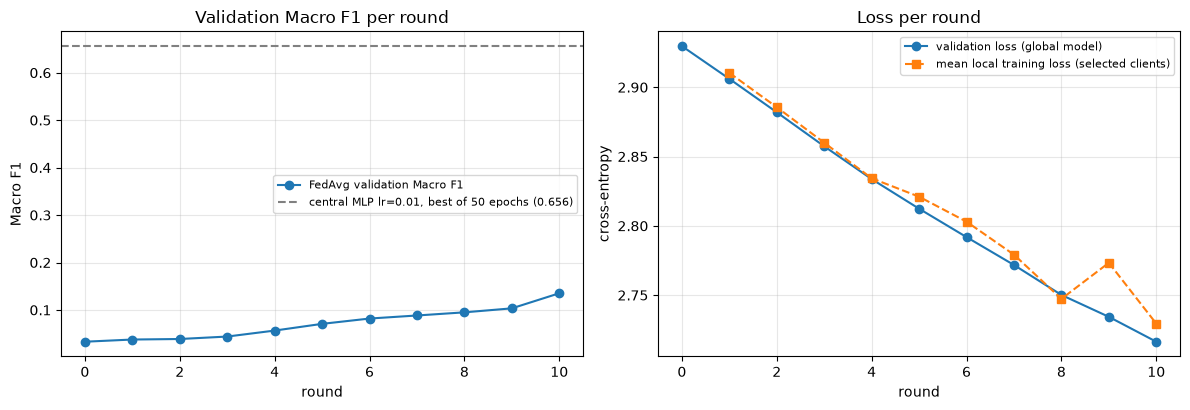

In [23]:
h = pd.read_csv(OUTPUT / "prototype_history.csv")
week3 = pd.read_csv(WEEK3 / "mlp_history.csv")
central_lr001 = week3[(week3.lr == 0.01) & (week3.epoch >= 1)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(h["round"], h["val_macro_f1"], "o-", label="FedAvg validation Macro F1")
axes[0].axhline(central_lr001.val_macro_f1.max(), ls="--", c="grey",
                label=f"central MLP lr=0.01, best of 50 epochs ({central_lr001.val_macro_f1.max():.3f})")
axes[0].set(xlabel="round", ylabel="Macro F1", title="Validation Macro F1 per round")
axes[1].plot(h["round"], h["val_loss"], "o-", label="validation loss (global model)")
axes[1].plot(h["round"], h["mean_local_loss"], "s--", label="mean local training loss (selected clients)")
axes[1].set(xlabel="round", ylabel="cross-entropy", title="Loss per round")
for ax in axes:
    ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUTPUT / "learning_curve.png", dpi=150)
plt.show()

## Runtime budget (`runtime_budget.md`)

Use **measured** numbers from `prototype_history.csv` to plan Week 5. Your markdown file should contain:

1. Hardware: CPU / machine name (`platform.processor()`, `platform.node()`), `torch.get_num_threads()`.
2. Measured seconds per round for 1 local epoch (use rounds 1-10; report mean and max).
3. Estimated time for **100 rounds** with 1 local epoch.
4. Estimated time for 100 rounds with **3** local epochs. Better than guessing "x3": *measure* a few rounds with
   `run_fedavg(3, local_epochs=3, tag="timing_E3")` and use that.
5. Total Week 5 budget: the two FedAvg candidates (E=1 and E=3, 100 rounds each) + anything else you plan to run
   (e.g. evaluation). Compare it with the time you actually have on your PC / laptop / Mini-PC.
6. Decision: keep the 100-round cap, or reduce it **uniformly** (same cap for both candidates) **before** any test
   evaluation, and write down why.

<details><summary>Hint</summary>

`h.loc[h["round"] >= 1, "round_time_s"].mean()` gives the mean round time. Build the markdown as an f-string and write it
with `(OUTPUT / "runtime_budget.md").write_text(text)`. Look at how Week 3 builds `error_analysis.md`.
</details>

In [48]:
hardware = {
    "machine": platform.node(), 
    "processor": platform.processor(),
    "torch_threads": torch.get_num_threads(),
    "torch_version": torch.__version__,
}

# 1 local epcoh measured
h = pd.read_csv(OUTPUT / "prototype_history.csv")
e1_times = h.loc[h["round"] >= 1, "round_time_s"]       # round 0 did no training
e1_mean, e1_max = e1_times.mean(), e1_times.max()

# 3 local epochs measured
TIMING_ROUNDS = 3
h3, _ = run_fedavg(TIMING_ROUNDS, local_epochs=3, tag="timing_E3")
e3_times = h3.loc[h3["round"] >= 1, "round_time_s"]
e3_mean, e3_max = e3_times.mean(), e3_times.max()

# Estimates for the planned 100-round cap
est_e1_s = e1_mean * PLANNED_ROUNDS
est_e3_s = e3_mean * PLANNED_ROUNDS
SAFETY = 1.5                                        # margin: slower machine, background programs
week5_total_s = SAFETY * (est_e1_s + est_e3_s)      # both candidates, each up to PLANNED_ROUNDS

# For comparison: what the Week 3 central MLP runs took
week3_cfg = json.loads((WEEK3 / "mlp_config.json").read_text())
central_s = sum(week3_cfg["runtime_s"].values())

AVAILABLE_S = 30 * 60      # YOUR CHOICE: compute time you can give the Week 5 runs (here 30 minutes)
fits = week5_total_s <= AVAILABLE_S
if fits:
    final_cap = PLANNED_ROUNDS
else:
    # Largest round count that fits: solve SAFETY * rounds * (e1_mean + e3_mean) <= AVAILABLE_S, round DOWN.
    # The same cap is used for BOTH candidates so they get an equal number of rounds.
    final_cap = min(PLANNED_ROUNDS, int(AVAILABLE_S / (SAFETY * (e1_mean + e3_mean))))

decision = (f"Keep the {PLANNED_ROUNDS}-round cap for both candidates: the estimated Week 5 total "
            f"({week5_total_s / 60:.1f} min including a {SAFETY}x margin) fits the available "
            f"{AVAILABLE_S / 60:.0f} min."
            if fits else
            f"Reduce the cap uniformly from {PLANNED_ROUNDS} to {final_cap} rounds for BOTH candidates: "
            f"the estimated total ({week5_total_s / 60:.1f} min) exceeds the available {AVAILABLE_S / 60:.0f} min. "
            f"This change is made before any test evaluation.")

# ---- 6. Write runtime_budget.md ----------------------------------------------------
text = f"""# Runtime budget (Week 4 -> Week 5)

## Hardware
- Machine: {hardware['machine']} ({hardware['processor']})
- PyTorch {hardware['torch_version']}, {hardware['torch_threads']} thread(s)

## Measured (FedAvg, {CLIENTS_PER_ROUND} clients per round, lr {LR}, batch {BATCH_SIZE})
Each round's time includes local training, aggregation, validation scoring and saving the checkpoint.
- 1 local epoch: {e1_mean:.3f} s per round (mean over rounds 1-{PROTOTYPE_ROUNDS}), max {e1_max:.3f} s
- 3 local epochs: {e3_mean:.3f} s per round (mean over a {TIMING_ROUNDS}-round timing run), max {e3_max:.3f} s
- Ratio E=3 / E=1: {e3_mean / e1_mean:.2f}x (less than 3x because aggregation and evaluation do not grow with local epochs)

## Estimates for {PLANNED_ROUNDS} rounds
- E=1: {est_e1_s:.1f} s ({est_e1_s / 60:.2f} min)
- E=3: {est_e3_s:.1f} s ({est_e3_s / 60:.2f} min)
- For comparison, the Week 3 central MLP runs took {central_s:.1f} s in total.

## Week 5 total
- Two candidates (E=1 and E=3), up to {PLANNED_ROUNDS} rounds each, x{SAFETY} safety margin:
  **{week5_total_s:.1f} s ({week5_total_s / 60:.2f} min)**
- Available compute time: {AVAILABLE_S / 60:.0f} min

## Decision
- {decision}
- Final round cap for Week 5: **{final_cap}** (frozen before test evaluation).
- Timings measured on this machine; re-measure if Week 5 runs on a different machine.
"""
(OUTPUT / "runtime_budget.md").write_text(text, encoding="utf-8")
print(text)


round   1: val Macro F1: 0.0450
round   2: val Macro F1: 0.0792
round   3: val Macro F1: 0.1055
# Runtime budget (Week 4 -> Week 5)

## Hardware
- Machine: DESKTOP-GOUTMJS (Intel64 Family 6 Model 170 Stepping 4, GenuineIntel)
- PyTorch 2.15.0+cpu, 1 thread(s)

## Measured (FedAvg, 10 clients per round, lr 0.01, batch 64)
Each round's time includes local training, aggregation, validation scoring and saving the checkpoint.
- 1 local epoch: 0.077 s per round (mean over rounds 1-10), max 0.094 s
- 3 local epochs: 0.156 s per round (mean over a 3-round timing run), max 0.182 s
- Ratio E=3 / E=1: 2.03x (less than 3x because aggregation and evaluation do not grow with local epochs)

## Estimates for 100 rounds
- E=1: 7.7 s (0.13 min)
- E=3: 15.6 s (0.26 min)
- For comparison, the Week 3 central MLP runs took 13.0 s in total.

## Week 5 total
- Two candidates (E=1 and E=3), up to 100 rounds each, x1.5 safety margin:
  **35.0 s (0.58 min)**
- Available compute time: 30 min

## Decision
- Keep t

## Self-check of all deliverables
Reads everything back from disk and checks it against the task sheet. 

In [49]:
problems = []
def need(cond, msg):
    if not cond:
        problems.append(msg)

# 1. Check logs: exist, enough checks, no FAIL.
for name, minimum in [("aggregation_checks.txt", 4), ("independence_checks.txt", 4)]:
    path = OUTPUT / name
    need(path.exists(), f"missing {name}")
    if path.exists():
        lines = [l for l in path.read_text().splitlines() if l.strip()]
        need(sum(l.startswith("PASS") for l in lines) >= minimum, f"{name}: fewer than {minimum} PASS lines")
        need(not any(l.startswith("FAIL") for l in lines), f"{name}: contains FAIL lines")
need("6.5" in (OUTPUT / "aggregation_checks.txt").read_text() if (OUTPUT / "aggregation_checks.txt").exists() else False,
     "aggregation_checks.txt should mention the 6.5 scalar check")

# 2. History: columns, rounds, sampling rules, sample counts.
h = pd.read_csv(OUTPUT / "prototype_history.csv", keep_default_na=False, na_values=[""])
need(set(REQUIRED_COLUMNS) <= set(h.columns), f"history missing columns {set(REQUIRED_COLUMNS) - set(h.columns)}")
need(list(h["round"]) == list(range(PROTOTYPE_ROUNDS + 1)), "history should have rounds 0..10")
for _, row in h[h["round"] >= 1].iterrows():
    users = [int(u) for u in str(row.selected_users).split(";")]
    counts = [int(n) for n in str(row.sample_counts).split(";")]
    need(len(users) == CLIENTS_PER_ROUND == len(set(users)), f"round {row['round']}: need {CLIENTS_PER_ROUND} distinct clients")
    need(set(users) <= set(CLIENT_IDS), f"round {row['round']}: non-training user selected")
    need(counts == [N_K[u] for u in users], f"round {row['round']}: sample_counts do not match the clients' window counts")
    need(row.total_samples == sum(counts), f"round {row['round']}: total_samples wrong")
need(h["elapsed_s"].is_monotonic_increasing, "elapsed_s should be cumulative")

# 3. Prototype checkpoint reproduces its recorded validation score; it is the best (earliest) round.
ckpt_path = OUTPUT / "fedavg_prototype.pt"
need(ckpt_path.exists(), "missing fedavg_prototype.pt")
if ckpt_path.exists():
    ck = torch.load(ckpt_path)
    rescored = evaluate_state(ck["state_dict"])["macro_f1"]
    need(np.isclose(rescored, ck["val_macro_f1"]), "checkpoint does not reproduce its val_macro_f1")
    hr = h[h["round"] >= 1]
    best_round = int(hr.loc[np.isclose(hr.val_macro_f1, hr.val_macro_f1.max()), "round"].min())
    need(ck["round"] == best_round, f"prototype round {ck['round']} is not the earliest best round {best_round}")
    need(np.isclose(h.set_index("round").loc[ck["round"], "val_macro_f1"], rescored), "history and checkpoint disagree")
    need(ck.get("label_order") == LABELS and ck.get("feature_order") == FEATURES, "checkpoint missing label/feature order")
need(len(list(CHECKPOINTS.glob("fedavg_round*.pt"))) >= PROTOTYPE_ROUNDS, "per-round checkpoints missing")

# 4. Other deliverables.
for f in ["learning_curve.png", "runtime_budget.md"]:
    need((OUTPUT / f).exists(), f"missing {f}")

print("\n".join(f"- {p}" for p in problems) if problems else "ALL CHECKS PASSED - Week 4 deliverables are complete")

ALL CHECKS PASSED - Week 4 deliverables are complete
